# Regression Project

For this project, we have compiled data on approximately 4,000 apartments in Tehran. All the data is authentic. Your task is to estimate the price (in either USD or Tomans) using the features provided in the dataset, which are described below. The data is stored in the file `housePrice.csv`.

Area (in square meters)

Number of bedrooms

Presence of parking (Yes/No)

Presence of a storage unit (Yes/No)

Presence of an elevator (Yes/No)

Approximate address in Tehran

Price in Tomans

Price in USD (`Price(USD)`)

Some entries in this dataset lack an address, and for others, the area has been entered incorrectly (showing an unrealistically large value). You must handle these cases by removing them from your dataset.

In [2]:
# importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.preprocessing import OneHotEncoder

In [3]:
# read csv file
df = pd.read_csv('house_price.csv')

In [6]:
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


In [8]:
df.isnull().sum()

Area           0
Room           0
Parking        0
Warehouse      0
Elevator       0
Address       23
Price          0
Price(USD)     0
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   object 
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   object 
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), object(2)
memory usage: 146.2+ KB


In [12]:
df.describe()

,Room,Price,Price(USD)
count,3479.000000,3.479000e+03,3.479000e+03
mean,2.079908,5.359023e+09,1.786341e+05
std,0.758275,8.099935e+09,2.699978e+05
min,0.000000,3.600000e+06,1.200000e+02
25%,2.000000,1.418250e+09,4.727500e+04
50%,2.000000,2.900000e+09,9.666667e+04
75%,2.000000,6.000000e+09,2.000000e+05
max,5.000000,9.240000e+10,3.080000e+06


In [14]:
df = df.dropna(how='any')
df.isnull().sum()

Area          0
Room          0
Parking       0
Warehouse     0
Elevator      0
Address       0
Price         0
Price(USD)    0
dtype: int64

In [16]:
# Converting units from Tomans to billions
df['new_price'] =df['Price'] / 1e9

In [18]:
# convert True and False to boolean 
df = df.astype({
    'Parking': int,
    'Warehouse': int,
    'Elevator': int
})
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD),new_price
0,63,1,1,1,1,Shahran,1.850000e+09,61666.67,1.8500
1,60,1,1,1,1,Shahran,1.850000e+09,61666.67,1.8500
2,79,2,1,1,1,Pardis,5.500000e+08,18333.33,0.5500
3,95,2,1,1,1,Shahrake Qods,9.025000e+08,30083.33,0.9025
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09,233333.33,7.0000


In [20]:
# see unique Areas for finding wrong areas
a = df['Area'].unique()
a

array(['63', '60', '79', '95', '123', '70', '87', '59', '54', '71', '68',
       '64', '136', '155', '140', '42', '93', '65', '99', '105', '160',
       '77', '110', '100', '90', '49', '96', '67', '62', '55', '129',
       '109', '58', '150', '130', '88', '51', '113', '98', '75', '61',
       '72', '122', '215', '101', '53', '74', '114', '151', '300', '76',
       '148', '40', '128', '94', '97', '137', '85', '78', '48', '82',
       '120', '139', '66', '80', '44', '50', '121', '141', '127', '180',
       '158', '144', '245', '190', '108', '117', '200', '125', '236',
       '220', '86', '84', '106', '320', '154', '210', '124', '83', '270',
       '104', '103', '165', '135', '132', '81', '153', '166', '175',
       '170', '115', '118', '116', '43', '230', '91', '126', '450', '500',
       '145', '112', '192', '164', '265', '92', '143', '350', '335',
       '235', '225', '221', '312', '188', '198', '650', '179', '256',
       '257', '167', '246', '168', '280', '69', '400', '660', '213', '

In [22]:
# drop wrong areas
df = df.sort_values('Area')
df.drop([807,709,2802,570,2171,1604],inplace=True)

In [24]:
# deleting areas that are greater than 400 
df['Area'] = df['Area'].astype(int)
df.sort_values(by='Area',inplace=True)
df = df.drop(df[df.Area > 400].index)
df.tail(10)

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD),new_price
1008,365,4,1,1,1,Dorous,4.745000e+10,1581666.67,47.450
1275,377,4,1,1,1,Elahieh,3.166800e+10,1055600.00,31.668
1723,380,4,1,1,1,Elahieh,5.000000e+10,1666666.67,50.000
768,400,3,1,1,0,Amirabad,2.000000e+09,66666.67,2.000
1270,400,5,1,1,0,Mirdamad,5.600000e+10,1866666.67,56.000
839,400,1,1,0,0,Shahedshahr,3.000000e+09,100000.00,3.000
742,400,5,1,1,1,Ekhtiarieh,1.850000e+10,616666.67,18.500
1438,400,5,1,1,0,Andisheh,1.100000e+10,366666.67,11.000
1863,400,4,1,1,1,Elahieh,6.300000e+10,2100000.00,63.000
430,400,5,1,1,0,Lavasan,8.500000e+10,2833333.33,85.000


# Model_1:feature_X :Area 

In [27]:
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD),new_price
3211,30,0,0,1,0,Ostad Moein,500000000.0,16666.67,0.50
2324,32,1,0,1,1,Eskandari,940000000.0,31333.33,0.94
2321,32,1,0,1,0,Hashemi,610000000.0,20333.33,0.61
2783,33,1,0,1,0,Beryanak,560000000.0,18666.67,0.56
2307,35,1,0,1,0,Salsabil,660000000.0,22000.00,0.66


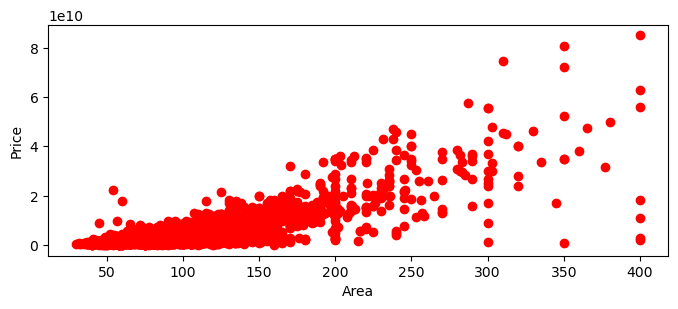

In [29]:
fig = plt.figure(figsize=[8,3])
ax1 = fig.add_subplot(111)
ax1.scatter(df.Area,df.Price,color='red')
ax1.set_xlabel('Area')
ax1.set_ylabel('Price')
plt.show()

In [30]:
# Data Partitioning to train and test
msk = np.random.RandomState(42).rand(len(df))<0.8
train = df[msk]
test = df[~msk]

In [33]:
train_x = np.asanyarray(train[['Area']])
train_y= np.asanyarray(train[['new_price']])
test_x = np.asanyarray(test[['Area']])
test_y = np.asanyarray(test[['new_price']])

In [35]:
# polynomial 
print(train_x[:3])
poly = PolynomialFeatures(degree=2)
train_x_poly = poly.fit_transform(train_x)
print(train_x_poly)

[[30]
 [32]
 [33]]
[[1.000e+00 3.000e+01 9.000e+02]
 [1.000e+00 3.200e+01 1.024e+03]
 [1.000e+00 3.300e+01 1.089e+03]
 ...
 [1.000e+00 4.000e+02 1.600e+05]
 [1.000e+00 4.000e+02 1.600e+05]
 [1.000e+00 4.000e+02 1.600e+05]]


In [37]:
reg = LinearRegression()
train_y_ = reg.fit(train_x_poly,train_y)
print('Coeficient',reg.coef_)
print('Intercept',reg.intercept_)

Coeficient [[0.         0.04685911 0.00020754]]
Intercept [-2.41596544]


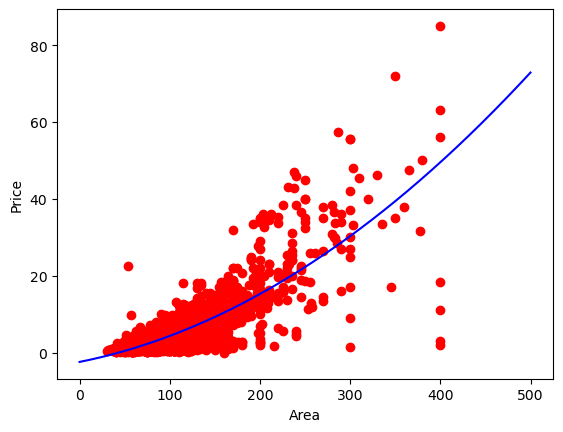

In [39]:
plt.scatter(train.Area,train.new_price,color='red')
XX = np.arange(0, 500, 0.1)
YY= reg.intercept_[0]+ reg.coef_[0][1]*XX+ reg.coef_[0][2]*np.power(XX, 2)
plt.plot(XX, YY, '-b')
plt.xlabel('Area')
plt.ylabel('Price')
plt.show()

In [41]:
# Test
test_x_poly = poly.fit_transform(test_x)
test_y_ = reg.predict(test_x_poly)
print("MAE:%.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("MSE:%.2f"% np.mean((test_y_-test_y)**2))
print("R2-Score:%.2f"% r2_score(test_y,test_y_))

MAE:2.27
MSE:18.17
R2-Score:0.67


# Model 2: x_feature:  Address

In [44]:
len(pd.unique(df.Address))

189

In [46]:
address_counts = df['Address'].value_counts(ascending = False)
address_counts = address_counts[:50]
# print(address_counts)

کدام محله ها نمونه های بیشتری دارند. اگر برای یک محله ما فقط 3 نمونه داشته باشیم تخمین قیمت مورد اعتماد نخواهد بود 


Analysis of Data Distribution
-


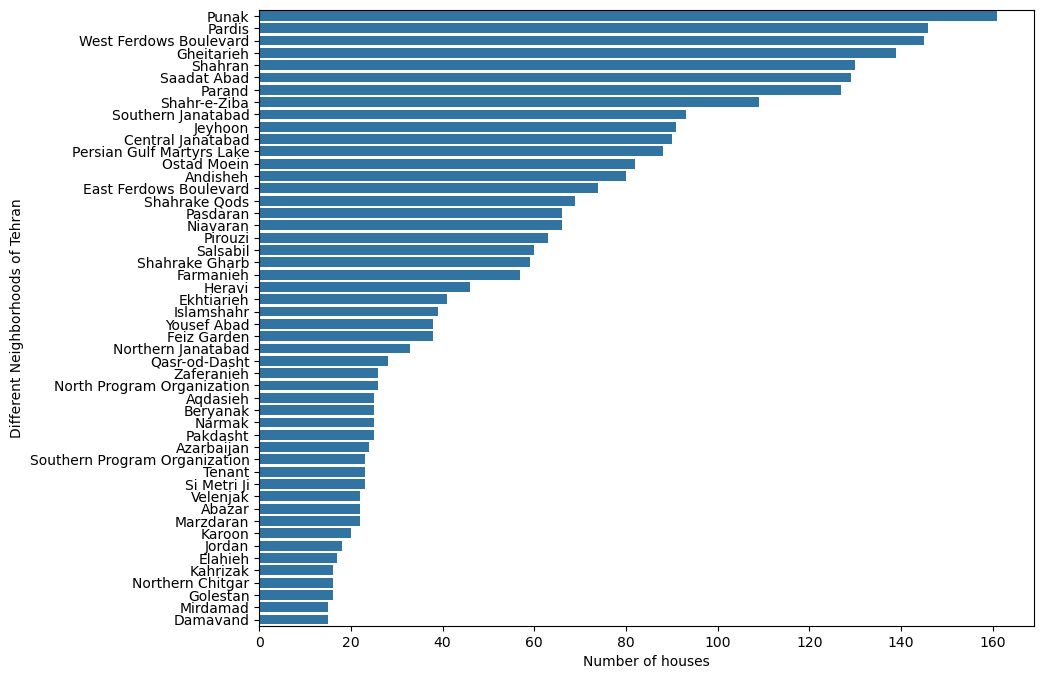

In [49]:
fig = plt.figure(figsize=(10,8))
ax = plt.subplot()
sns.barplot(x=address_counts.values,y= address_counts.index)
plt.xlabel('Number of houses')
plt.ylabel('Different Neighborhoods of Tehran')
plt.show()

Mean of house price in different Nighborhoods
--

In [52]:
address_mean = df[df['Address'].isin(address_counts.index)].groupby('Address')['new_price'].mean()
address_mean = address_mean.sort_values(ascending=False)
# print(address_mean)

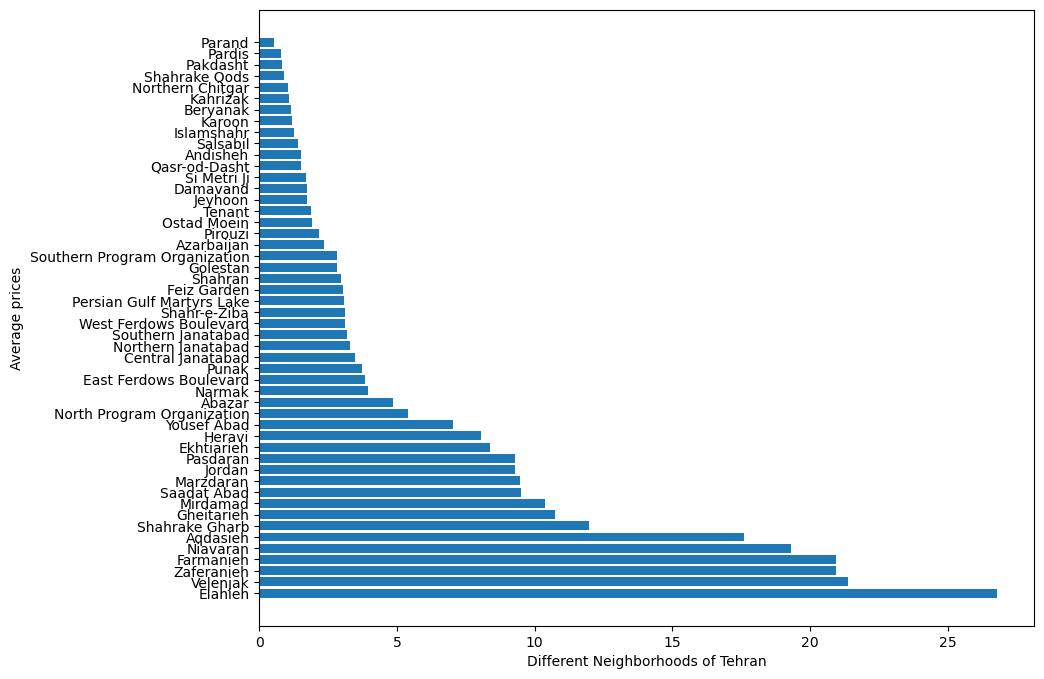

In [54]:
plt.figure(figsize=(10,8))
plt.barh(address_mean.index,address_mean.values)
plt.xlabel('Different Neighborhoods of Tehran')
plt.ylabel('Average prices')
plt.show()

In [56]:
# median
address_median = df[df['Address'].isin(address_counts.index)].groupby('Address')['new_price'].median()
address_median = address_median.sort_values(ascending=False)

# print(address_median)


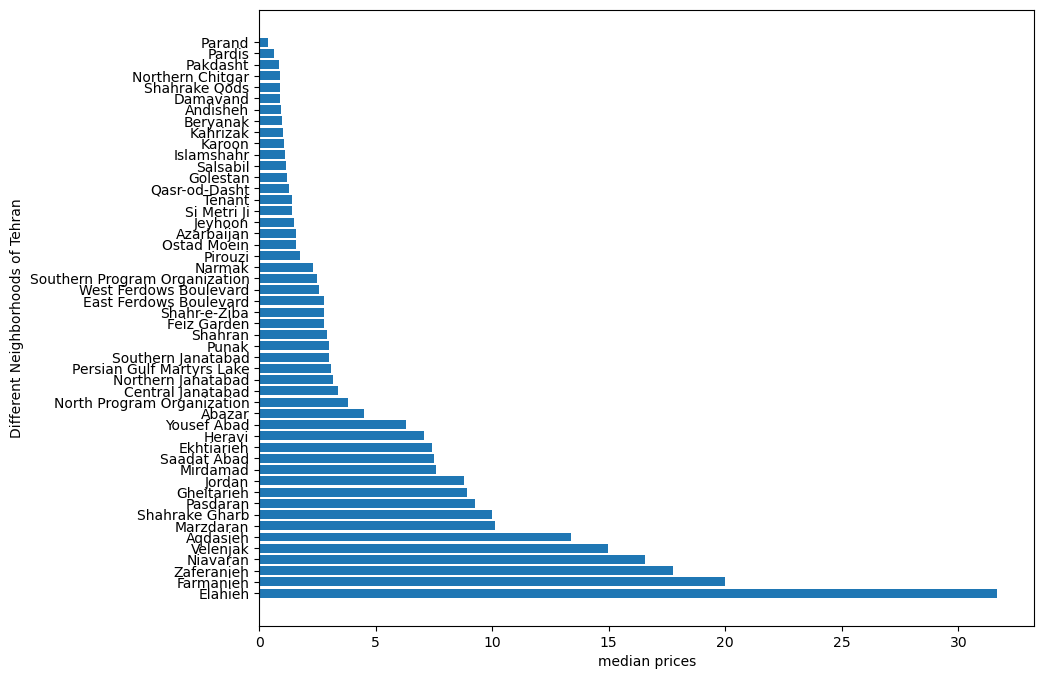

In [58]:
plt.figure(figsize=(10,8))
plt.barh(address_median.index,address_median.values)
plt.ylabel('Different Neighborhoods of Tehran')
plt.xlabel('median prices')
plt.show()

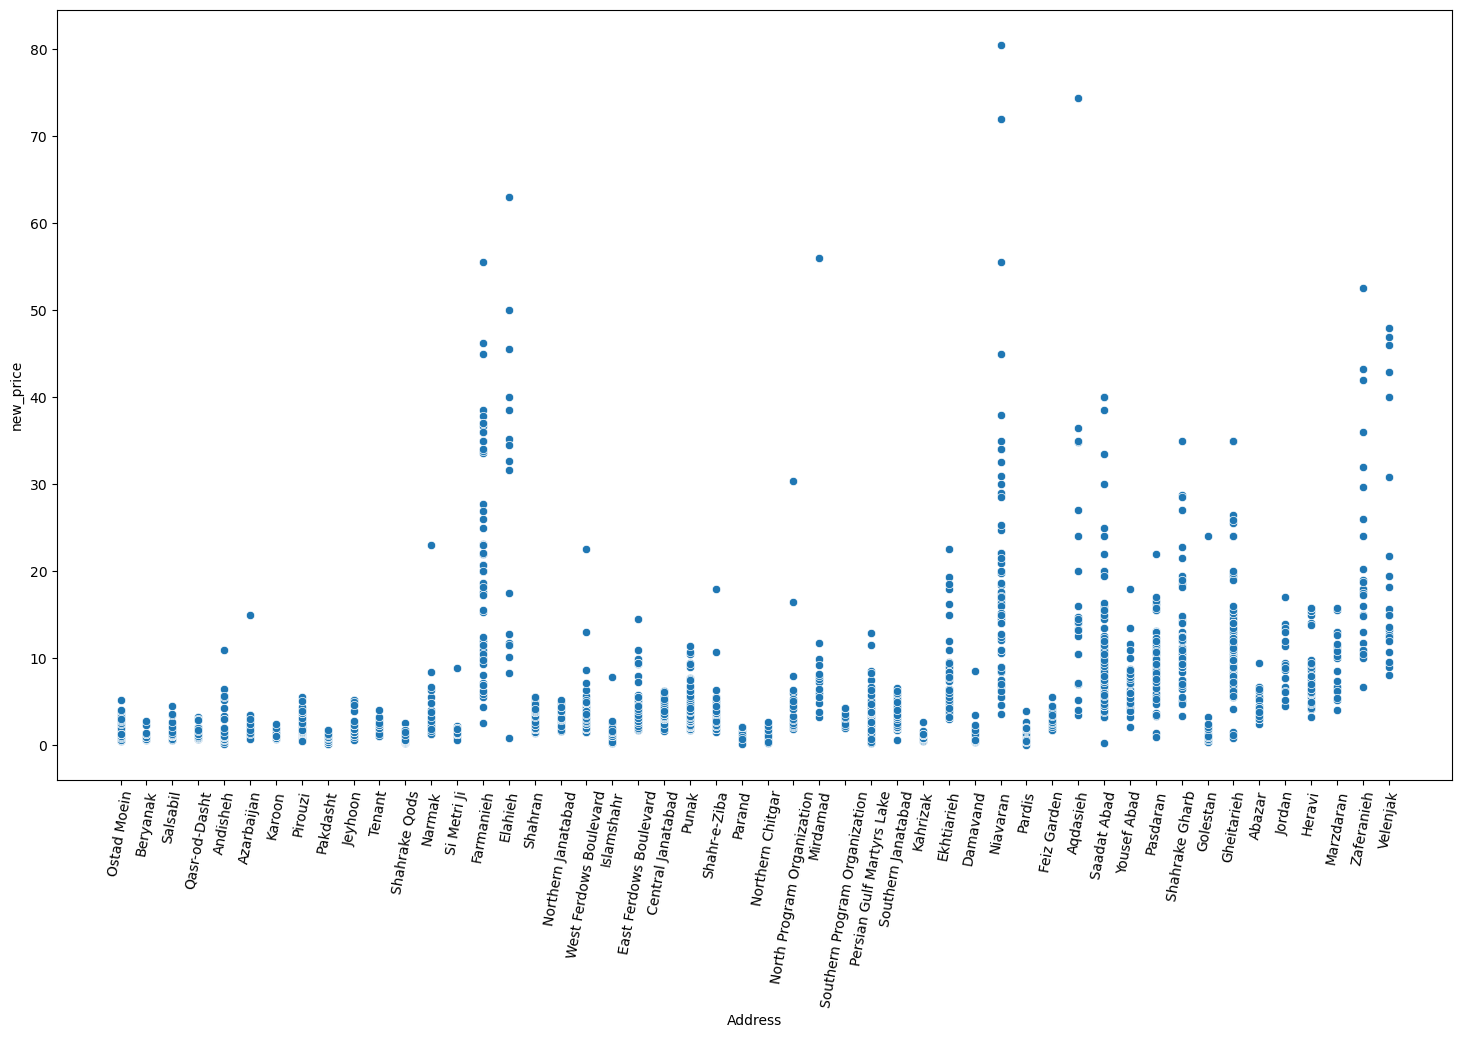

In [60]:
plot_df = df[df['Address'].isin(address_counts.index)]
plt.figure(figsize=(18,10))
sns.scatterplot(
    data=plot_df,
    x='Address',
    y='new_price'
)

plt.xticks(rotation=80)
plt.show()

In [62]:
# Select neighborhoods with more than 40 houses
selected_address = df['Address'].value_counts()
selected_address = selected_address[selected_address > 40].index

# Keep only selected neighborhoods
df_model = df[df['Address'].isin(selected_address)].copy()


In [64]:
from sklearn.preprocessing import OneHotEncoder
# one hot encoding Adresses
categorical_columns = ['Address']
# print(categorical_columns)
# creating an object from OneHotEncoder class(it will convert categorical to 0-1)
# sparse_output=False --> the output be a numpy array not sparse matrix
encoder = OneHotEncoder(sparse_output=False, drop='first')
# fit: it identifies and learns the categorical values present in the data.
# transform: them in to 0 and 1
# the output is numpy array
encoded_data = encoder.fit_transform(df_model[categorical_columns])
# make dataframe and produce the new names of columns
# combining dataframes
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=df_model.index
)

In [66]:
from sklearn.model_selection import train_test_split
# X: neighborhood features
X = encoded_df
# # Y: house prices
y = df_model['new_price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    # every time we split data it will be the same as before
    random_state=42
)

In [68]:
from sklearn import linear_model
reg = linear_model.LinearRegression()
reg.fit(X_train,y_train)
print('coeffiecent:',reg.coef_)
print('Intercept:',reg.intercept_)

coeffiecent: [ 1.89795377  2.11820317  7.01707042 18.45689956  9.3970393   6.54664151
  0.19570428 18.58373352  0.40447609 -1.08554293 -0.78436703  7.79985661
  1.38954281  0.49820847  2.25684087  7.68736908 -0.16766842  1.43346547
  9.97255705 -0.67401564  1.4569039   1.59975476  1.52536149]
Intercept: 1.5717174603174522


In [101]:
from sklearn.metrics import r2_score, mean_absolute_error

predictions = reg.predict(X_test)

print("Residual sum of squares: %.2f"
      % np.mean((predictions - y_test) ** 2))

# Explained variance score: 1 is perfect prediction
print('Variance score: %.2f' % reg.score(X_test, y_test))


Residual sum of squares: 18.84
Variance score: 0.55


Model 3 : features:Area+rooms+Parking+Elevator
--

In [73]:
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD),new_price
3211,30,0,0,1,0,Ostad Moein,500000000.0,16666.67,0.50
2324,32,1,0,1,1,Eskandari,940000000.0,31333.33,0.94
2321,32,1,0,1,0,Hashemi,610000000.0,20333.33,0.61
2783,33,1,0,1,0,Beryanak,560000000.0,18666.67,0.56
2307,35,1,0,1,0,Salsabil,660000000.0,22000.00,0.66


In [75]:
msk = np.random.RandomState(42).rand(len(df))<0.8
train = df[msk]
test = df[~msk]

In [77]:
train_x = np.asanyarray(train[['Area','Parking','Elevator','Warehouse','Room']])
train_y = np.asanyarray(train['new_price'])
test_x = np.asanyarray(test[['Area','Parking','Elevator','Warehouse','Room']])
test_y = np.asanyarray(test['new_price'])

In [79]:
from sklearn import linear_model

model_A_r= linear_model.LinearRegression()
model_A_r.fit(train_x,train_y)
print('coefficent:',model_A_r.coef_)
print('Intercept:',model_A_r.intercept_)

coefficent: [ 0.12615103  0.09170177  0.26732926  0.70232807 -1.44717217]
Intercept: -5.768119038847446


In [81]:
# prediction
y_pred = model_A_r.predict(test_x)
print("Residual sum of squares: %.2f"
      % np.mean((y_pred - test_y) ** 2))

# Explained variance score: 1 is perfect prediction
print('Variance score: %.2f' % model_A_r.score(test_x, test_y))

Residual sum of squares: 19.59
Variance score: 0.65


# Model 4 : Model 2 features+ Address

In [84]:
# Select neighborhoods with more than 40 houses
selected_address = df['Address'].value_counts()
# print(selected_address)
selected_address = selected_address[selected_address > 40].index
# print(selected_address)
df_model = df[df['Address'].isin(selected_address)].copy()

In [86]:
# one hot encoding addresses
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoded_data = encoder.fit_transform(df_model[['Address']])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['Address']),
    index=df_model.index
)
# print(encoded_data)
# print(encoded_df)
# print(df_model)

In [88]:
msk = np.random.RandomState(42).rand(len(df_model))<0.8
train = df_model[msk]
test = df_model[~msk]

چون هر ردیف در دیتافریم یک شماره شاخص (Index) دارد. ما با این دستور می‌گوییم فقط ردیف‌هایی از encoded_df را انتخاب کن که شماره‌شان در train وجود دارد.

In [106]:
train_x = np.asanyarray(pd.concat([train[['Area','Parking','Elevator','Warehouse','Room']],encoded_df.loc[train.index]],axis=1))
train_y= np.asanyarray(train['new_price'])
test_x =  np.asanyarray(pd.concat([test[['Area','Parking','Elevator','Warehouse','Room']],encoded_df.loc[test.index]],axis=1))
test_y= np.asanyarray(test['new_price'])

In [108]:
model_4 = linear_model.LinearRegression()
model_4.fit(train_x,train_y)
print('Coefficent:',model_4.coef_)
print('Intercept:',model_4.intercept_)

Coefficent: [ 0.10447069 -0.48544779 -0.2763184  -1.37769788  3.4358412   3.14320811
  4.5889174  11.16864395  5.94585056  3.26491939  2.69379541 11.93199855
  2.47120837  0.54544024 -0.41286601  4.23530276  0.57013764  2.50798602
  3.63206838  5.71303913  2.83036854  3.04936158  7.70176229  0.01526738
  3.06775105  3.42471841  3.57257848]
Intercept: -5.441762268922756


In [110]:
y_hat= model_4.predict(test_x)
print("Residual sum of squares: %.2f"
      % np.mean((y_hat - test_y) ** 2))

# Explained variance score: 1 is perfect prediction
print('Variance score: %.2f' % model_4.score(test_x, test_y))


Residual sum of squares: 5.93
Variance score: 0.85


## Model Performance Comparison and Conclusion

Four regression models were developed and evaluated to predict house prices.

The first model used Polynomial Regression with the house area as its only input feature and achieved an R² score of **0.67 (67%)**.

The final model incorporated all available features, including Area, Room, Parking, Warehouse, Elevator, and Neighborhood. The categorical Neighborhood feature was transformed using **One-Hot Encoding**. This model achieved the best performance, with an R² score of **0.85 (85%)**.

Overall, the results indicate that incorporating additional property features and neighborhood information improved the model's predictive performance. The final model outperformed the other three models and provided the most accurate predictions among the evaluated approaches.